<!-- colab-badge -->
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Zeshengliu213/ai-for-materials/blob/main/02%20-%20Supervised%20Learning/02e_validation_and_tuning.ipynb)

# 02e · 模型验证、调参与适用域：从论文高分到真实泛化

在 `02a`–`02d` 中，我们已经配齐了线性模型、kNN、SVM、随机森林、XGBoost 与逻辑回归全套武器库。但在把模型写进论文或交给合成实验室使用之前，还有三个决定科研成败的灵魂拷问：
1. **一次随机 8:2 划分的成绩靠得住吗？**——换个随机种子分数晃动多少？怎样在 **K 折交叉验证** 与 **超参数调优（`GridSearchCV`）** 中用 **`Pipeline`** 彻底杜绝数据泄漏？
2. **现在误差还有点大，再花半年多测 1000 个分子值得吗？**——怎样用 **学习曲线（Learning Curve）** 定量诊断瓶颈？
3. **面对一个全新母核或更大共轭尺寸的新分子，模型的预测到底能不能信？**——怎样用 **Murcko 骨架划分（Scaffold Split）**、**尺寸外推测试**与 **Tanimoto 适用域（Applicability Domain）** 给每个预测贴上可信度标签？

### 本节内容
1. 从单次划分的随机波动到 5 折交叉验证（5-Fold CV）
2. 审稿人头号雷区：用 `Pipeline` 杜绝交叉验证中的数据泄漏（现场对比演示）
3. 超参数网格搜索（`GridSearchCV`）与调参的真实边际收益
4. 学习曲线（`learning_curve`）：该补实验数据，还是该换特征/模型？
5. 更严苛的泛化大考：**Murcko 骨架划分（Scaffold Split）** 与 **跨共轭尺寸外推考验**
6. **适用域（Applicability Domain）**：给有机半导体候选分子做可信度体检

In [1]:
# colab-setup (本地运行时自动跳过)
import os, sys

if "google.colab" in sys.modules:
    _repo_dir = "/content/ai-for-materials"
    if not os.path.exists(_repo_dir):
        os.system("git clone --depth 1 https://github.com/Zeshengliu213/ai-for-materials.git " + _repo_dir)
    os.chdir(os.path.join(_repo_dir, "02 - Supervised Learning"))
    get_ipython().run_line_magic("pip", "install -q rdkit")


## 0. 环境准备与读取 AqSolDB 数据

In [2]:
try:
    import rdkit
except ImportError:
    %pip install -q rdkit
    import rdkit

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from rdkit import Chem, DataStructs, RDLogger
from rdkit.Chem import Descriptors, rdFingerprintGenerator
from rdkit.Chem.Scaffolds import MurckoScaffold

from sklearn.model_selection import (
    train_test_split, KFold, cross_val_score, GridSearchCV,
    learning_curve, GroupShuffleSplit,
)
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import root_mean_squared_error

RDLogger.DisableLog("rdApp.*")

<!-- ai4m-style -->
> **📘 课程统一绘图风格**：下面这格加载课程自带的 `ai4m.mplstyle`（配色与课程网站同源，无上右边框，仅横向浅网格，保存默认 300 dpi）。`C` 是课程配色，手动指定颜色时写 `color=C.crimson`。


In [3]:
# ai4m-style：课程统一绘图风格（本地与 Colab 通用）
import pathlib, sys

sys.path.insert(0, str(pathlib.Path.cwd().parent))   # course/ 根目录
import ai4m_style as ai4m

C = ai4m.use()        # 应用 ai4m.mplstyle，返回课程配色


In [4]:
DATA_FILE = "data/solubility.csv" if os.path.exists("data/solubility.csv") else "../01 - Basics/data/solubility.csv"
df = pd.read_csv(DATA_FILE)
df["mol"] = df["SMILES"].apply(Chem.MolFromSmiles)
df = df[df["mol"].notna()].reset_index(drop=True)

feature_cols = [
    "MolWt", "MolLogP", "MolMR", "HeavyAtomCount", "NumHAcceptors", "NumHDonors",
    "NumHeteroatoms", "NumRotatableBonds", "NumValenceElectrons", "NumAromaticRings",
    "NumSaturatedRings", "NumAliphaticRings", "RingCount", "TPSA", "LabuteASA",
    "BalabanJ", "BertzCT",
]
X = df[feature_cols].values
y = df["Solubility"].values
idx_train, idx_test = train_test_split(np.arange(len(df)), test_size=0.2, random_state=42)
X_train, X_test = X[idx_train], X[idx_test]
y_train, y_test = y[idx_train], y[idx_test]

---
## 1. 从单次划分的随机波动到 K 折交叉验证（K-Fold CV）

在 `02c` 里，我们固定 `random_state=42` 得到随机森林测试集 $\text{RMSE} = 1.17$。如果模型原封不动，仅仅把划分数据的随机种子换成 `0, 1, 2, 3, 4`（重新洗牌抽 20% 分子当考卷），分数会晃动多少？

为了消除单次抽样的运气成分、同时**绝不偷看锁在保险柜里的最终测试集 `X_test`**，标准做法是在**训练集 `X_train` 内部**做 **5 折交叉验证（5-Fold Cross-Validation）**：把 `X_train` 均分 5 份，轮流拿 1 份当验证卷、其余 4 份当训练卷，汇报 **`均值 ± 标准差`**：

In [5]:
seed_rmses = []
for seed in [0, 1, 2, 3, 4]:
    Xa, Xb, ya, yb = train_test_split(X, y, test_size=0.2, random_state=seed)
    rf_tmp = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1).fit(Xa, ya)
    seed_rmses.append(root_mean_squared_error(yb, rf_tmp.predict(Xb)))
print("5 个不同随机种子单次切分的测试 RMSE:", np.round(seed_rmses, 3))
print(f"单次切分极差波动: {max(seed_rmses) - min(seed_rmses):.3f} logS 单位！")
print()

cv = KFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = -cross_val_score(
    RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
    X_train, y_train, cv=cv, scoring="neg_root_mean_squared_error", n_jobs=-1,
)
print("训练集内部 5 折各自的验证 RMSE:", cv_scores.round(3))
print(f"规范汇报格式 -> 5-Fold CV RMSE = {cv_scores.mean():.3f} ± {cv_scores.std():.3f}")

5 个不同随机种子单次切分的测试 RMSE: [1.155 1.185 1.167 1.178 1.102]
单次切分极差波动: 0.083 logS 单位！



训练集内部 5 折各自的验证 RMSE: [1.053 1.164 1.143 1.14  1.183]
规范汇报格式 -> 5-Fold CV RMSE = 1.137 ± 0.045


---
## 2. 用 `Pipeline` 杜绝交叉验证中的数据泄漏（现场抓包演示！）

在材料信息学审稿中，最常见的拒稿硬伤之一叫做**交叉验证前预处理泄漏（Preprocessing Leakage）**：
- **❌ 错误做法**：先把整个训练集做特征筛选或标准化 `X_scaled = scaler.fit_transform(X_train)`，然后再把 `X_scaled` 喂给 `cross_val_score`！这样每一折训练时都已经偷看了当前验证折的均值、方差或标签相关性。
- **✅ 正确做法**：用 `make_pipeline(预处理步骤, 模型)` 把它们捆绑成一个整体——在 5 折交叉验证的每一轮里，`Pipeline` 会自动**只在当前 4 份训练折上 `fit` 预处理器**，再去 `transform` 那 1 份验证折！

为了让你刻骨铭心地看到数据泄漏有多可怕，我们做一个经典的对照实验：生成 **80 个纯随机噪声样本、2000 个纯随机特征与完全无关的随机标签 $y$**（真实可预测规律严格为 0，真实 $R^2$ 理应 $\le 0$！），对比“先在全集挑前 10 个最相关特征再做 5 折 CV”与“放进 `Pipeline` 里再做 5 折 CV”：

In [6]:
# ▶️ 运行看看：纯随机噪声上，“先预处理再 CV”竟然凭空捏造出 R² > 0.4 的虚假发现！
rng_leak = np.random.default_rng(2026)
X_noise = rng_leak.normal(size=(80, 2000))   # 纯随机高斯白噪声特征
y_noise = rng_leak.normal(size=80)          # 与 X 毫无关系的纯随机标签！

# ❌ 错误做法：在交叉验证外部先偷看全部 100 个样本挑出 Top-10 特征
X_leaked = SelectKBest(f_regression, k=15).fit_transform(X_noise, y_noise)
fake_r2 = cross_val_score(Ridge(), X_leaked, y_noise, cv=5, scoring="r2").mean()

# ✅ 正确做法：把特征筛选与标准化锁进 Pipeline，每折内部独立挑选
clean_pipe = make_pipeline(StandardScaler(), SelectKBest(f_regression, k=15), Ridge())
true_r2 = cross_val_score(clean_pipe, X_noise, y_noise, cv=5, scoring="r2").mean()

print(f"❌ 泄漏做法（CV 前做特征选择）5 折平均 R² = {fake_r2:+.3f}  <-- 凭空捏造的假阳性信号！")
print(f"✅ 规范 Pipeline（每折内部独立处理）5 折平均 R² = {true_r2:+.3f}  <-- 诚实反映纯属噪声！")

❌ 泄漏做法（CV 前做特征选择）5 折平均 R² = +0.347  <-- 凭空捏造的假阳性信号！
✅ 规范 Pipeline（每折内部独立处理）5 折平均 R² = -0.768  <-- 诚实反映纯属噪声！


这个对照实验值得所有材料研究生引以为戒：**在小样本（$N=80$）、多描述符（$p=2000$）的材料课题中，一旦把预处理写在 `Pipeline` 外面，哪怕拿一堆随机数都能跑出 $R^2 \approx 0.45$ 的“漂亮论文图”！**

---
## 3. 超参数网格搜索（`GridSearchCV`）与学习曲线（`learning_curve`）

### 📘 3.1 只在训练集上用 `GridSearchCV` 调参

区分**模型参数**（`fit` 自动学出的权重/分裂点）与**超参数**（人工设定的树深 `max_depth`、树数 `n_estimators`、kNN 的 `k`）。调参铁律是 `GridSearchCV` **只能喂入 `X_train, y_train`**，选出冠军后再去 `X_test` 上考最后一次试。

### 📘 3.2 学习曲线：回答导师“再多测 1000 个分子值不值得？”

`learning_curve` 按 5%、10%、25%、50%、100% 递增抽取训练样本，画出训练误差与交叉验证误差随数据量增长的走势：

GridSearchCV 最优超参数: {'max_depth': 20, 'min_samples_leaf': 1} | 最优 5-Fold CV RMSE = 1.136
最终独立测试集 RMSE = 1.170


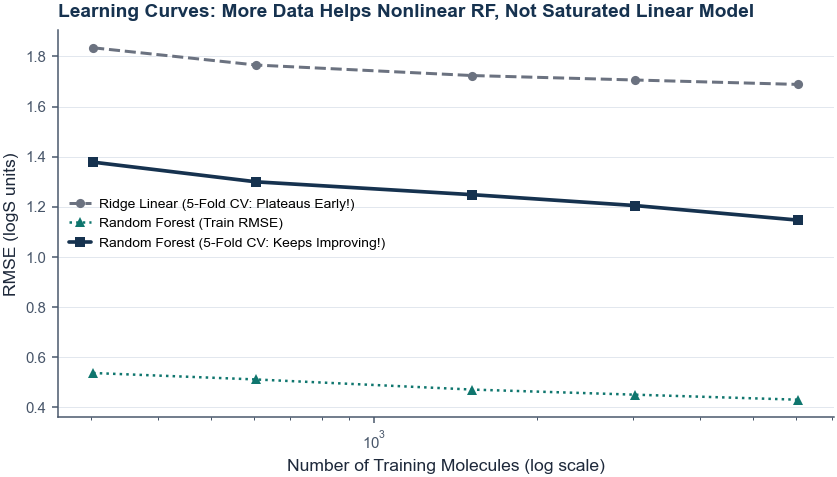

In [7]:
# 1. 对随机森林做轻量 5 折网格搜索
grid_rf = GridSearchCV(
    RandomForestRegressor(n_estimators=80, random_state=42, n_jobs=-1),
    param_grid={"max_depth": [6, 12, 20], "min_samples_leaf": [1, 4]},
    cv=cv,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
).fit(X_train, y_train)

print(f"GridSearchCV 最优超参数: {grid_rf.best_params_} | 最优 5-Fold CV RMSE = {-grid_rf.best_score_:.3f}")
print(f"最终独立测试集 RMSE = {root_mean_squared_error(y_test, grid_rf.best_estimator_.predict(X_test)):.3f}")

# 2. 绘制学习曲线：对比线性 Ridge（很快饱和）与非线性随机森林（随数据增加持续进步！）
sizes, tr_ridge, val_ridge = learning_curve(
    make_pipeline(StandardScaler(), Ridge(alpha=50.0)), X_train, y_train,
    train_sizes=[0.05, 0.1, 0.25, 0.5, 1.0], cv=5, scoring="neg_root_mean_squared_error", n_jobs=-1,
)
_, tr_rf, val_rf = learning_curve(
    RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1), X_train, y_train,
    train_sizes=[0.05, 0.1, 0.25, 0.5, 1.0], cv=5, scoring="neg_root_mean_squared_error", n_jobs=-1,
)

fig, ax = plt.subplots(figsize=(7.0, 4.0))
ax.plot(sizes, -val_ridge.mean(axis=1), "o--", color=C.slate, lw=1.8, label="Ridge Linear (5-Fold CV: Plateaus Early!)")
ax.plot(sizes, -tr_rf.mean(axis=1), "^:", color=C.teal, lw=1.5, label="Random Forest (Train RMSE)")
ax.plot(sizes, -val_rf.mean(axis=1), "s-", color=C.navy, lw=2.2, label="Random Forest (5-Fold CV: Keeps Improving!)")
ax.set_xscale("log")
ax.set_xlabel("Number of Training Molecules (log scale)")
ax.set_ylabel("RMSE (logS units)")
ax.set_title("Learning Curves: More Data Helps Nonlinear RF, Not Saturated Linear Model")
ax.legend(fontsize=8.3)
plt.show()

看上图两条验证曲线的鲜明对比：
- **灰色虚线（线性 Ridge）**：样本超过 400 个之后就彻底躺平在 `1.66`——因为瓶颈在于线性假设太简单（高偏差），此时再砸钱测一万个分子也毫无意义，应该换非线性模型或补强物理特征！
- **深蓝实线（随机森林）**：从 300 个分子一直到 6000 个分子仍在对数轴上稳步下降——说明非线性模型还没“吃饱”，继续扩充高质量数据依然有利可图。

---
## 4. 更严苛的泛化大考：Murcko 骨架划分与跨共轭尺寸外推

随机划分会把同母核衍生物（如邻/间/对氯苯胺）拆到训练和测试两边让模型“沾光”。在真实新材料探索中，我们必须用两场更严苛的大考检验模型：
1. **Murcko 骨架划分（Scaffold Split，兑现 `01d` 伏笔）**：提取每个分子的 Bemis–Murcko 核心骨架，用 `GroupShuffleSplit` 强制**同一骨架的所有衍生物要么全进训练集、要么全进测试集**；
2. **跨尺寸外推划分（Size Extrapolation Split）**：只给模型看**芳香环数 $\le 2$** 的小分子（8647 个），考它预测**芳香环数 $\ge 4$** 的大共轭分子（261 个）！

17 Global Descriptors  | Random Split RMSE = 1.180  -->  Scaffold Split RMSE = 1.200 (退化 +0.021)


2048-bit Morgan FP     | Random Split RMSE = 1.523  -->  Scaffold Split RMSE = 1.791 (退化 +0.268)


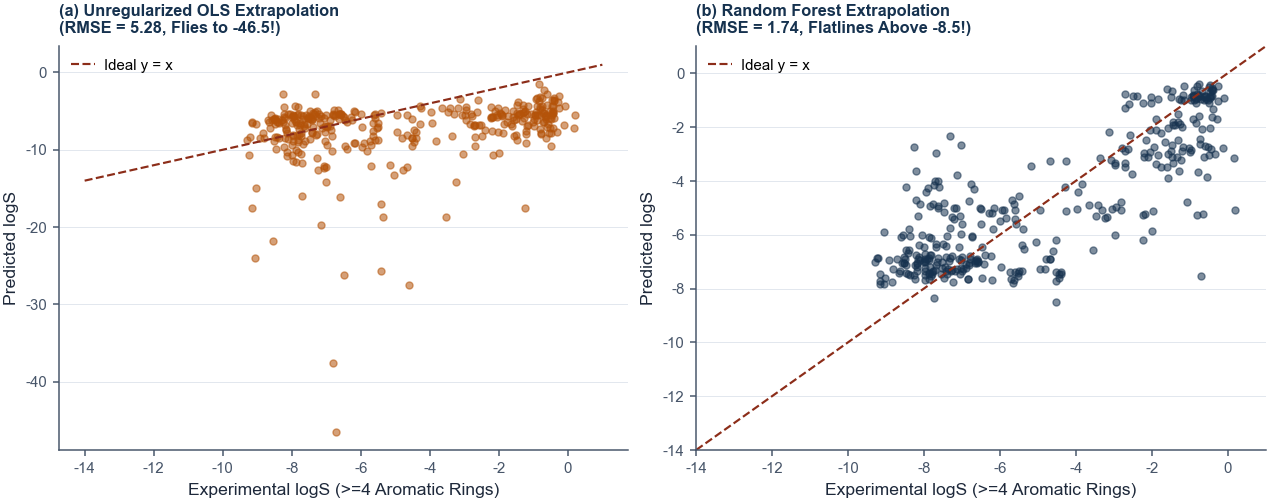

In [8]:
# 1. Murcko 骨架划分 vs 随机划分（同时对比 17 描述符 vs 2048 二值指纹受骨架切换的冲击！）
scaffolds = df["mol"].apply(lambda m: MurckoScaffold.MurckoScaffoldSmiles(mol=m)).replace("", "acyclic")
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
scaf_tr, scaf_te = next(gss.split(X, y, groups=scaffolds))

fp_gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
fp_bit = np.array([fp_gen.GetFingerprintAsNumPy(m) for m in df["mol"]], dtype=np.float32)

for feat_name, F in [("17 Global Descriptors", X), ("2048-bit Morgan FP", fp_bit)]:
    m_rand = RandomForestRegressor(n_estimators=60, max_depth=16, random_state=42, n_jobs=-1).fit(F[idx_train], y[idx_train])
    m_scaf = RandomForestRegressor(n_estimators=60, max_depth=16, random_state=42, n_jobs=-1).fit(F[scaf_tr], y[scaf_tr])
    r_rand = root_mean_squared_error(y[idx_test], m_rand.predict(F[idx_test]))
    r_scaf = root_mean_squared_error(y[scaf_te], m_scaf.predict(F[scaf_te]))
    print(f"{feat_name:22s} | Random Split RMSE = {r_rand:.3f}  -->  Scaffold Split RMSE = {r_scaf:.3f} (退化 +{r_scaf - r_rand:.3f})")

# 2. 跨共轭尺寸外推考验：Train (<=2 aromatic rings) -> Test (>=4 aromatic rings)
n_arom = df["NumAromaticRings"].values
small_m, large_m = (n_arom <= 2), (n_arom >= 4)

ols_ext = LinearRegression().fit(X[small_m], y[small_m]).predict(X[large_m])
rf_ext = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1).fit(X[small_m], y[small_m]).predict(X[large_m])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.6, 4.2))
for ax, pred, col, title in [
    (ax1, ols_ext, C.gold, f"(a) Unregularized OLS Extrapolation\n(RMSE = {root_mean_squared_error(y[large_m], ols_ext):.2f}, Flies to {ols_ext.min():.1f}!)"),
    (ax2, rf_ext, C.navy, f"(b) Random Forest Extrapolation\n(RMSE = {root_mean_squared_error(y[large_m], rf_ext):.2f}, Flatlines Above {rf_ext.min():.1f}!)"),
]:
    ax.scatter(y[large_m], pred, s=18, alpha=0.55, color=col)
    ax.plot([-14, 1], [-14, 1], "--", color=C.crimson, lw=1.3, label="Ideal y = x")
    ax.set_xlabel("Experimental logS (>=4 Aromatic Rings)")
    ax.set_ylabel("Predicted logS")
    ax.set_title(title, fontsize=9.8)
    ax.legend(loc="upper left")
ax2.set_xlim(-14, 1)
ax2.set_ylim(-14, 1)
plt.show()

注意上面两个极具含金量的实验发现：
1. **全局物理化学描述符的抗骨架切换能力显著强于局部指纹**：切换到陌生 Murcko 骨架时，2048 维二值指纹的误差退化幅度远大于 17 个全局物理化学描述符（因为陌生骨架的子结构比特模型没见过，但它的 `MolLogP` 和 `MolWt` 物理意义依然通用！）；
2. **外推双双失灵**：未正则化 OLS 顺着共线权重飞到了 `-46`（地球海洋里连半个分子都容不下），而随机森林则把所有 $\log S \in [-13, -8]$ 的极难溶大共轭分子齐刷刷“托底”高估在了 `-7` 以上！

---
## 5. 适用域（Applicability Domain）：给每个预测贴上可信度标签

当合成同事拿来一个新分子让你预测时，务必同时检查它与训练集的**最大 Tanimoto 结构相似度**以及**核心描述符分位数**，判断它是否落在模型的**适用域（Applicability Domain, AD）**内：

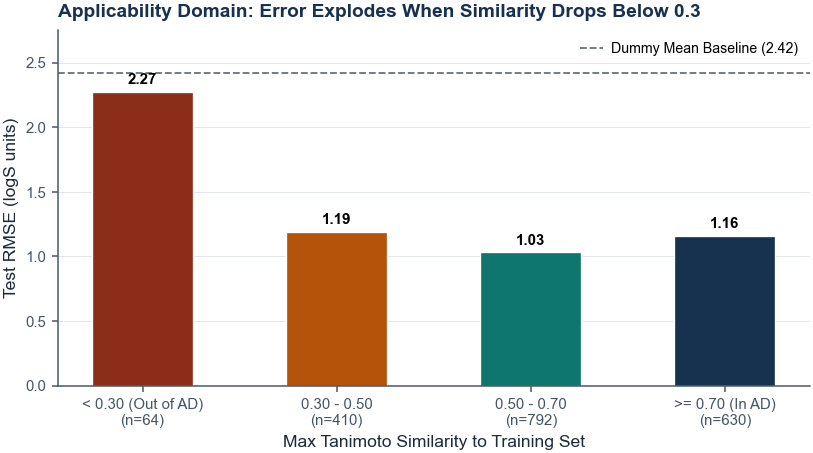

       Candidate  Max_BitFP_Sim      Closest_Train_Mol  MolLogP LogP_Pct_in_Train
       Pentacene          1.000            naphthacene     6.30             94.0%
3-Hexylthiophene          0.517         n-hexylbenzene     3.87             80.4%
            BTBT          0.667       dibenzothiophene     5.27             90.3%
         C8-BTBT          0.457         4-heptylphenol    11.08             98.9%
         Rubrene          0.471    biphenyl;  diphenyl    11.81             99.1%
  TIPS-Pentacene          0.367 dibenzo[a,c]anthracene    13.44             99.4%
            EDOT          0.391     Dibenzo-18-crown-6     1.52             41.4%


In [9]:
train_fps = [fp_gen.GetFingerprint(df["mol"][i]) for i in idx_train]
test_max_sim = np.array([
    max(DataStructs.BulkTanimotoSimilarity(fp_gen.GetFingerprint(df["mol"][i]), train_fps))
    for i in idx_test
])

rf_base = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1).fit(X_train, y_train)
test_preds = rf_base.predict(X_test)

bins = [(0.0, 0.3, "< 0.30 (Out of AD)"), (0.3, 0.5, "0.30 - 0.50"), (0.5, 0.7, "0.50 - 0.70"), (0.7, 1.01, ">= 0.70 (In AD)")]
bin_labels, bin_rmses, bin_counts = [], [], []
for lo, hi, label in bins:
    m = (test_max_sim >= lo) & (test_max_sim < hi)
    bin_labels.append(f"{label}\n(n={m.sum()})")
    bin_rmses.append(root_mean_squared_error(y_test[m], test_preds[m]))
    bin_counts.append(m.sum())

fig, ax = plt.subplots(figsize=(6.8, 3.8))
bars = ax.bar(bin_labels, bin_rmses, color=[C.crimson, C.gold, C.teal, C.navy], width=0.52)
ax.axhline(2.42, color=C.slate, ls="--", lw=1.1, label="Dummy Mean Baseline (2.42)")
ax.set_ylabel("Test RMSE (logS units)")
ax.set_xlabel("Max Tanimoto Similarity to Training Set")
ax.set_title("Applicability Domain: Error Explodes When Similarity Drops Below 0.3")
ax.set_ylim(0, 2.75)
for b, v in zip(bars, bin_rmses):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.06, f"{v:.2f}", ha="center", fontsize=9.0, fontweight="bold")
ax.legend(fontsize=8.5)
plt.show()

# 对 7 个代表性有机半导体候选分子做双维度适用域体检（结构相似度 + MolLogP 越界分位）
osc_candidates = {
    "Pentacene": "c1ccc2cc3cc4cc5ccccc5cc4cc3cc2c1",
    "3-Hexylthiophene": "CCCCCCc1ccsc1",
    "BTBT": "c1ccc2c(c1)sc1c2sc2ccccc21",
    "C8-BTBT": "CCCCCCCCc1ccc2c(c1)sc1c3ccc(CCCCCCCC)cc3sc21",
    "Rubrene": "c1ccc(cc1)-c1c2ccccc2c(-c2ccccc2)c2c(-c3ccccc3)c3ccccc3c(-c3ccccc3)c12",
    "TIPS-Pentacene": "CC(C)[Si](C#Cc1c2cc3ccccc3cc2c(C#C[Si](C(C)C)(C(C)C)C(C)C)c2cc3ccccc3cc12)(C(C)C)C(C)C",
    "EDOT": "C1COc2cscc2O1",
}
train_logp = df["MolLogP"].values[idx_train]
ad_rows = []
for name, smi in osc_candidates.items():
    mol = Chem.MolFromSmiles(smi)
    sims = DataStructs.BulkTanimotoSimilarity(fp_gen.GetFingerprint(mol), train_fps)
    best_i = int(np.argmax(sims))
    lp = Descriptors.MolLogP(mol)
    ad_rows.append({
        "Candidate": name,
        "Max_BitFP_Sim": round(sims[best_i], 3),
        "Closest_Train_Mol": df["Name"].iloc[idx_train[best_i]][:24],
        "MolLogP": round(lp, 2),
        "LogP_Pct_in_Train": f"{(train_logp < lp).mean() * 100:.1f}%",
    })
print(pd.DataFrame(ad_rows).to_string(index=False))

> **🚨 抓出表里第一行的“虚假满分”陷阱**：
> `TIPS-Pentacene`、`C8-BTBT`、`Rubrene` 的 `MolLogP` 超过了训练集 **98.8% 以上**的分子，一眼就能识别出处于适用域边缘；唯独第一行 **`Pentacene`（并五苯）** 显示它与训练集中并四苯的二值指纹相似度高达 **`1.000`**！这正是我们在 `01d` 抓到过的二值指纹盲区——如果用来测适用域的尺子本身丢掉了重复单元个数，就会给出致命的虚假安全感！

---
### 🏋️ 练习 02e-1：用防泄漏 `Pipeline + GridSearchCV` 调优 kNN

创建一个 `make_pipeline(StandardScaler(), KNeighborsRegressor())`，在训练集 `X_train, y_train` 上用 5 折 `GridSearchCV` 搜索以下超参数网格：
- `"kneighborsregressor__n_neighbors"`: `[3, 5, 10, 20]`
- `"kneighborsregressor__weights"`: `["uniform", "distance"]`
打印选出的 `best_params_`、最优 5 折 CV RMSE，以及该最优流水线在最终测试集 `X_test, y_test` 上的 RMSE。（参考答案见 `solutions/02_supervised_solutions.ipynb`）

In [10]:
# 在这里写你的代码（练习 02e-1）


### 🏋️ 练习 02e-2：改用计数指纹（Count FP）修复并五苯的适用域盲区

改用 `fp_gen.GetCountFingerprint(mol)` 重新生成训练集计数指纹列表 `train_cfps`，并调用 `DataStructs.BulkTanimotoSimilarity` 重新计算上面 `osc_candidates` 中 7 个有机半导体分子与训练集的最大相似度，验证 `Pentacene` 的相似度从虚假的 `1.000` 回落到真实水平！

In [11]:
# 在这里写你的代码（练习 02e-2）


---
## 模块 02 总结与下一章预告

至此，我们已经完成了经典监督学习从底层数学几何直觉到材料防坑实战的完整拼图：
- **算法全景**：线性回归/梯度下降/Ridge&Lasso（`02a`）$\to$ kNN 与 SVM/RBF 核（`02b`）$\to$ 决策树、随机森林与 XGBoost（`02c`）$\to$ 感知机、逻辑回归与分类决策体系（`02d`）；
- **防坑护城河**：`Pipeline` 严防预处理泄漏、5 折交叉验证带误差棒汇报、学习曲线诊断数据瓶颈、Murcko 骨架划分与计数指纹适用域体检（`02e`）。

请接着完成 **`02f_exercises.ipynb` 综合实战习题**检验本章所学！
**👉 下一章预告（`03 - Unsupervised Learning`）**：如果手里有成千上万个候选分子或催化剂配体，却**没有任何现成的实验标签 $y$**，怎样画出一张直观的二维“化学空间地图”并自动发现隐藏的新家族？我们将进入降维与聚类的世界！